# Lab 4: Engineering Data Analysis with Pandas

Last time out we looked at reading numerical data contained in CSV files into numpy and performing some analysis on the datasets. Numpy excels at this sort of operation. Where it struggles is mixed datasets i.e. data with columns of different types, especially non-numeric. These mixed data are often referred to as structured data. Such data are remarkably common - for a lot of work we can use Excel, but for large data sets we need a way to handle this in python.

## Pandas

Pandas (link: [Documentation here](https://pandas.pydata.org/docs/user_guide/index.html)) is an extremely widely used python library for handling/analysing structured data. For many of its operations it uses numpy but does all the preparitory work for you so that your code remains readable. Other libraries for structured data are available (Polars, Dask, PySpark, etc.) in some applications these have advantages, but Pandas is the market leader and many of the alternatives essentially copy the syntax of pandas and their advantages come from how they work in the background. We are going to work with Pandas here.

Numpy is built around the array structure. Pandas is built round a data structure known as a `dataframe`. Users of `R` may have cone across this concept with that language. A dataframe is a data set that can have columns of data of different types, the columns can have titles. 


## Getting started

We can import pandas in the usual way. It is usually given the shortname `pd`.

```python
import pandas as pd
```
Let's import pandas and then import a file from last week's lab session:

In [1]:
import pandas as pd
from pathlib import Path
# Resolve absolute path to the dataset assuming a 'data' folder next to the notebook
data_dir = Path("data").resolve() # the path to the data folder
file_path = data_dir / "L3DataTensile.csv" # specify which file in the data folder

df = pd.read_csv(file_path)  # a dataframe called df - this is where our data is stored


Notice that there was no skipping of lines - this is possible, but in this data set we can just use the data as it comes.

To get a quick look at the top of the dataframe use `dataframeName.head()`. This gives a nicely formatted view of the first few rows of the dataframe:

In [2]:
df.head()

,Force(N),Distance(mm)
0,650.5,0.00000
1,650.5,0.00000
2,650.5,0.00000
3,650.5,0.00275
4,707.0,0.00825


Notice we now have an index column and the data columns have titles from the original data.

Pandas can read and write (create) files of many different types - including Excel files and tables. A quick introduction to Pandas and files is here (link: [Pandas: getting started with files](https://pandas.pydata.org/docs/getting_started/intro_tutorials/02_read_write.html#)).

### A bit of computing terminology: methods
Python is an Object Oriented Programming (OOP) language. For this module we will generally not worry about what this means. For this module the bit we need to know is that for non-OOP languages variables are places that information is stored whereas OOP variables - often referred to as objects - have the information plus a range of built-in functionality - known as methods. In the above `read_csv()` and `head()` are methods that Pandas dataframes possess. Where ever you see something of the form: `var_name.function_name()` then `function_name()` is a method of the object `var_name`. 

#### Why is this important?
The methods in pandas do a lot of work for you. One key advantage that they bring is that most methods will work on the dataframe (or defined subsection of) without having to worry about loops etc to go through each row. In fact, if you do attempt to loop through a dataframe you are likely to make your code several orders of magnitude slower. This might not matter for a few tens of data, but it rapidly becomes an issues as the size of the data increases.

### back to the code.

The method `tail()` displays the last few lines of the dataframe:


In [3]:
df.tail(10) # look at last 10 lines of the dataframe

,Force(N),Distance(mm)
5123,25196.5,28.38375
5124,25071.0,28.38925
5125,25071.0,28.39550
5126,24896.5,28.40100
5127,24722.0,28.40675
5128,24630.0,28.41275
5129,24428.5,28.41850
5130,24428.5,28.42475
5131,24273.5,28.43100
5132,383.5,28.43650


Another method gives summary statistics (where possible)

In [4]:
df.describe()

,Force(N),Distance(mm)
count,5133.000000,5133.000000
mean,27270.387882,13.705570
std,6359.543871,8.281797
min,383.500000,0.000000
25%,25019.500000,6.451750
50%,29615.500000,13.378250
75%,31512.500000,20.907500
max,31953.000000,28.436500


## Filtering data
Pandas uses a square bracket syntax to access different parts of a dataframe. At its simplest it is similar to the notation used for numpy, but it is much more powerful.

A single column in a dataframe can be obtained by referring to its name:

In [5]:
force = df["Force(N)"]
force.head()

0    650.5
1    650.5
2    650.5
3    650.5
4    707.0
Name: Force(N), dtype: float64

Let's get the rows for which the force generated is less than 1kN:


In [6]:
below1k = df[df["Force(N)"] < 1000] # filter rows where the force is less than 1kN
below1k.head()

,Force(N),Distance(mm)
0,650.5,0.00000
1,650.5,0.00000
2,650.5,0.00000
3,650.5,0.00275
4,707.0,0.00825


Other conditional tests can be used `>`, `==`, etc.

There's more on filtering, reshaping, etc of dataframes here (link: [Intro to slicing dataframes](https://pandas.pydata.org/docs/getting_started/intro_tutorials/03_subset_data.html#)

## Plotting with Pandas

Since visualisation is a key partof data anaysis Pandas comes with some decent tools "out of the box".

<Axes: >

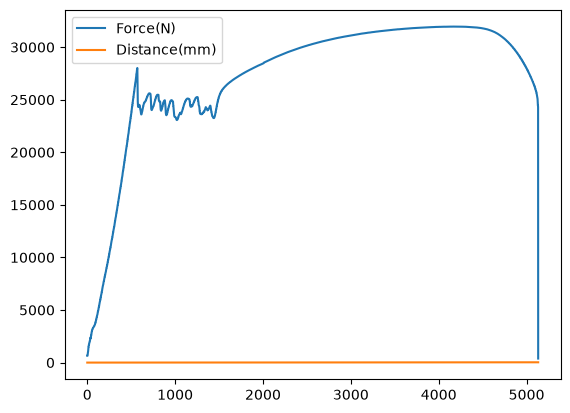

In [7]:
df.plot()

That's not the most useful plot. Lets focus on the force data:

<Axes: >

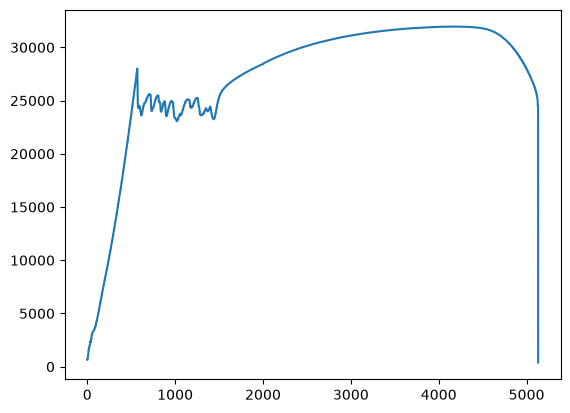

In [8]:
df["Force(N)"].plot() # use a method on a subset of a dataframe

That's better, but we can do more:

<Axes: xlabel='Distance(mm)', ylabel='Force(N)'>

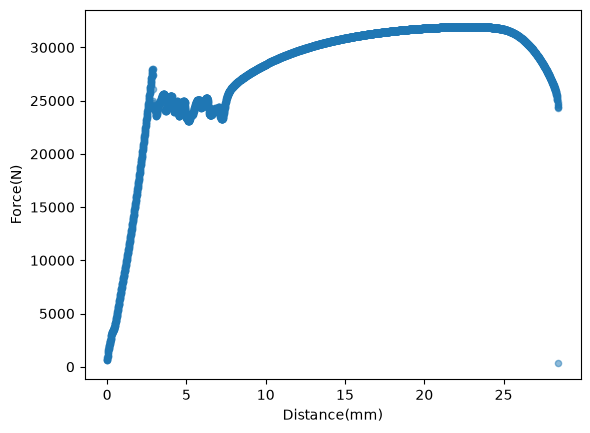

In [9]:
df.plot.scatter(x="Distance(mm)", y="Force(N)", alpha=0.5)

Notice in the last bit of python code there are two methods `plot` and `scatter`. The `plot` method gives a line plot by default, but it has other methods associated with it. In this case `scatter()` was used. 

Pandas is capable of a a wide range of plot types. More details here: (link: [Intro to Pandas plotting](https://pandas.pydata.org/docs/getting_started/intro_tutorials/04_plotting.html#)

As mentioned in last week's tutorial session the library seaborn brings lots of plot types (with pretty default settings). It works well with both numpy and pandas.

## Accessing dataframe elements
We can access numpy array elements using numbers in square brackets e.g.

```numpy_array_name[23][531]```

It is slightly more complicated in pandas. In pandas there are two main ways to access specific (sets of) cells in a dataframe.

### loc[]

The `loc[]` method provides a way to access cells using the labels of a dataframe. To see how this works we are going to use a dataframe borrowed from [link: geeksforgeeks](https://www.geeksforgeeks.org/machine-learning/difference-between-loc-and-iloc-in-pandas-dataframe/)


In [10]:

# creating a sample dataframe
data = pd.DataFrame({'Brand': ['Maruti', 'Hyundai', 'Tata',
                               'Mahindra', 'Maruti', 'Hyundai',
                               'Renault', 'Tata', 'Maruti'],
                     'Year': [2012, 2014, 2011, 2015, 2012,
                              2016, 2014, 2018, 2019],
                     'Kms Driven': [50000, 30000, 60000,
                                    25000, 10000, 46000,
                                    31000, 15000, 12000],
                     'City': ['Gurgaon', 'Delhi', 'Mumbai',
                              'Delhi', 'Mumbai', 'Delhi',
                              'Mumbai', 'Chennai',  'Ghaziabad'],
                     'Mileage':  [28, 27, 25, 26, 28,
                                  29, 24, 21, 24]})

# displaying the DataFrame
display(data) # show all of the dataframe

,Brand,Year,Kms Driven,City,Mileage
0,Maruti,2012,50000,Gurgaon,28
1,Hyundai,2014,30000,Delhi,27
2,Tata,2011,60000,Mumbai,25
3,Mahindra,2015,25000,Delhi,26
4,Maruti,2012,10000,Mumbai,28
5,Hyundai,2016,46000,Delhi,29
6,Renault,2014,31000,Mumbai,24
7,Tata,2018,15000,Chennai,21
8,Maruti,2019,12000,Ghaziabad,24


In [11]:
display(data.loc[1: 3]) # use the index to give a range of rows

,Brand,Year,Kms Driven,City,Mileage
1,Hyundai,2014,30000,Delhi,27
2,Tata,2011,60000,Mumbai,25
3,Mahindra,2015,25000,Delhi,26


In [12]:
display(data.loc[(data.Brand == 'Maruti')]) # select a brand

,Brand,Year,Kms Driven,City,Mileage
0,Maruti,2012,50000,Gurgaon,28
4,Maruti,2012,10000,Mumbai,28
8,Maruti,2019,12000,Ghaziabad,24


In [13]:
display(data.loc[(data.Brand == 'Maruti') & (data.Mileage == 24)]) # extend the filtering

,Brand,Year,Kms Driven,City,Mileage
8,Maruti,2019,12000,Ghaziabad,24


### iloc[]
The `iloc[]` method provides something close to numpy style element access i.e. integers are used to specify the a cell (or range of). 

The simplest form takes a list of integers that specify first the row and then the column. 

Remember that python indices start from 0.

e.g.

In [14]:
display(data.iloc[1,3]) 

'Delhi'


## Working with numpy

Many of the methods that pandas provides use numpy behind the scenes. You often will need to create numpy arrays from a dataframe (or part of a dataframe) to use with another library that expects to get a numpy array e.g. scikit-learn. To make this easy pandas has the method `to_numpy()`

In [15]:
df.to_numpy() # returns a 2D numpy array

array([[  650.5    ,     0.     ],
       [  650.5    ,     0.     ],
       [  650.5    ,     0.     ],
       ...,
       [24428.5    ,    28.42475],
       [24273.5    ,    28.431  ],
       [  383.5    ,    28.4365 ]], shape=(5133, 2))

In [16]:
df["Force(N)"].to_numpy() # returns 1D numpy array

array([  650.5,   650.5,   650.5, ..., 24428.5, 24273.5,   383.5],
      shape=(5133,))

## Creating copies

Dataframes have methods for creating copies of themselves. For non OOP languages a line such as 

`x = y`


will put a copy of whatever is stored in `y` in a new variable `x` and these variables are independent of each other. With OOP's objects life is not so simple. The syntax above will work with Pandas objects, but there's more going on than we might expect. Initially `x` will just provide a way of accessing the same memory that is used to store `y` - it is what is known as a shallow copy. As soon as you attempt to change the value of any part of `x` python/pandas will make a copy of the data and associate that copy with `x` only. This new copy is a deep copy. A deep copy creates a new object, this is much less confusing when you are getting started, but given that ojects can be massive (many times the size of the memory in your computer) this can cause significant performance issues. In your programming you will almost always want a deep copy and this is what pandas defaults to. Behind the scenes for things like sending objects to functions etc. python/pandas is likely to use a shallow copy. The code below shows how to make deep and shallow copies.

In [17]:

# use df from above

dfNew1 = df.copy()            # deep copy
dfNew2 = df         # shallow copy n.b. dfNew2 = df.copy(False) also makes a shallow copy
